# WineQualityClassifier

#### Contexte et Objectif
La qualité d’un vin est influencée par de nombreux paramètres physicochimiques tels que l’acidité, le pH, le taux d’alcool ou encore la teneur en sucre résiduel.
 L’objectif de ce projet est de développer un modèle de classification
supervisé capable de prédire la qualité du vin (sur une échelle de 0 à 10, ou sous forme binaire : bon/mauvais) à partir de ces caract´eristiques
mesurables.


#### Données
Les données utilisées sont open-source et tirées du Wine Quality dataset présent sur la plateforme du UC Irvine Machine Learning Repository

In [25]:
import urllib.request

url_names = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality.names"

# Récupération et affichage du contenu texte
with urllib.request.urlopen(url_names) as response:
    content = response.read().decode('utf-8', errors='ignore')

print(content)

Citation Request:
  This dataset is public available for research. The details are described in [Cortez et al., 2009]. 
  Please include this citation if you plan to use this database:

  P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. 
  Modeling wine preferences by data mining from physicochemical properties.
  In Decision Support Systems, Elsevier, 47(4):547-553. ISSN: 0167-9236.

  Available at: [@Elsevier] http://dx.doi.org/10.1016/j.dss.2009.05.016
                [Pre-press (pdf)] http://www3.dsi.uminho.pt/pcortez/winequality09.pdf
                [bib] http://www3.dsi.uminho.pt/pcortez/dss09.bib

1. Title: Wine Quality 

2. Sources
   Created by: Paulo Cortez (Univ. Minho), Antonio Cerdeira, Fernando Almeida, Telmo Matos and Jose Reis (CVRVV) @ 2009
   
3. Past Usage:

  P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. 
  Modeling wine preferences by data mining from physicochemical properties.
  In Decision Support Systems, Elsevier, 47(4):547-553. ISSN: 016

### Prétraitement des données

#### Installation, import des bibliothèques, des jeux de données et statistiques descriptives


In [26]:
#Installation des bibliothèques
!pip install pandas numpy matplotlib seaborn missingno


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
#Import des bibliothèques
import pandas as pd
import numpy as np
np.set_printoptions(suppress=True) #format de flottant
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import missingno as msno
warnings.filterwarnings("ignore")

SEED = 42   # graine fixée pour la reproductibilité des résultats

Plusieurs étapes sont aléatoires (découpage des données, validation croisée, Random Search). Avec random_state=SEED partout, on obtiendra les mêmes résultats à chaque exécution.

In [28]:
# Chargement du vin rouge
url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df_red = pd.read_csv(url_red, sep=';')

print(df_red.head())


   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [29]:
df_red.columns = [c.replace(" ", "_") for c in df_red.columns]
# renommage des noms de colonnes "fixed acidity" -> "fixed_acidity"

df_red.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         1599 non-null   float64
 1   volatile_acidity      1599 non-null   float64
 2   citric_acid           1599 non-null   float64
 3   residual_sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free_sulfur_dioxide   1599 non-null   float64
 6   total_sulfur_dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


Au vu des informations du dataset de vin rouge, on semble avoir les bons formats de données.

In [30]:
# Chargement du vin blanc
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
df_white = pd.read_csv(url_white, sep=';')

print (df_white.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.0              0.27         0.36            20.7      0.045   
1            6.3              0.30         0.34             1.6      0.049   
2            8.1              0.28         0.40             6.9      0.050   
3            7.2              0.23         0.32             8.5      0.058   
4            7.2              0.23         0.32             8.5      0.058   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 45.0                 170.0   1.0010  3.00       0.45   
1                 14.0                 132.0   0.9940  3.30       0.49   
2                 30.0                  97.0   0.9951  3.26       0.44   
3                 47.0                 186.0   0.9956  3.19       0.40   
4                 47.0                 186.0   0.9956  3.19       0.40   

   alcohol  quality  
0      8.8        6  
1      9.5        6  
2     10.1        6 

In [31]:
df_white.columns = [c.replace(" ", "_") for c in df_white.columns] #Renommage des noms de colonnes # "fixed acidity" -> "fixed_acidity"

df_white.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         4898 non-null   float64
 1   volatile_acidity      4898 non-null   float64
 2   citric_acid           4898 non-null   float64
 3   residual_sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free_sulfur_dioxide   4898 non-null   float64
 6   total_sulfur_dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


A la vu des information du dataset de vin blanc, on semble aussi avoir les bons formats de données.

##### Gestion de valeurs manquantes et détection de valeurs aberrantes et doublons

(1599, 12)
Valeurs manquantes : 0


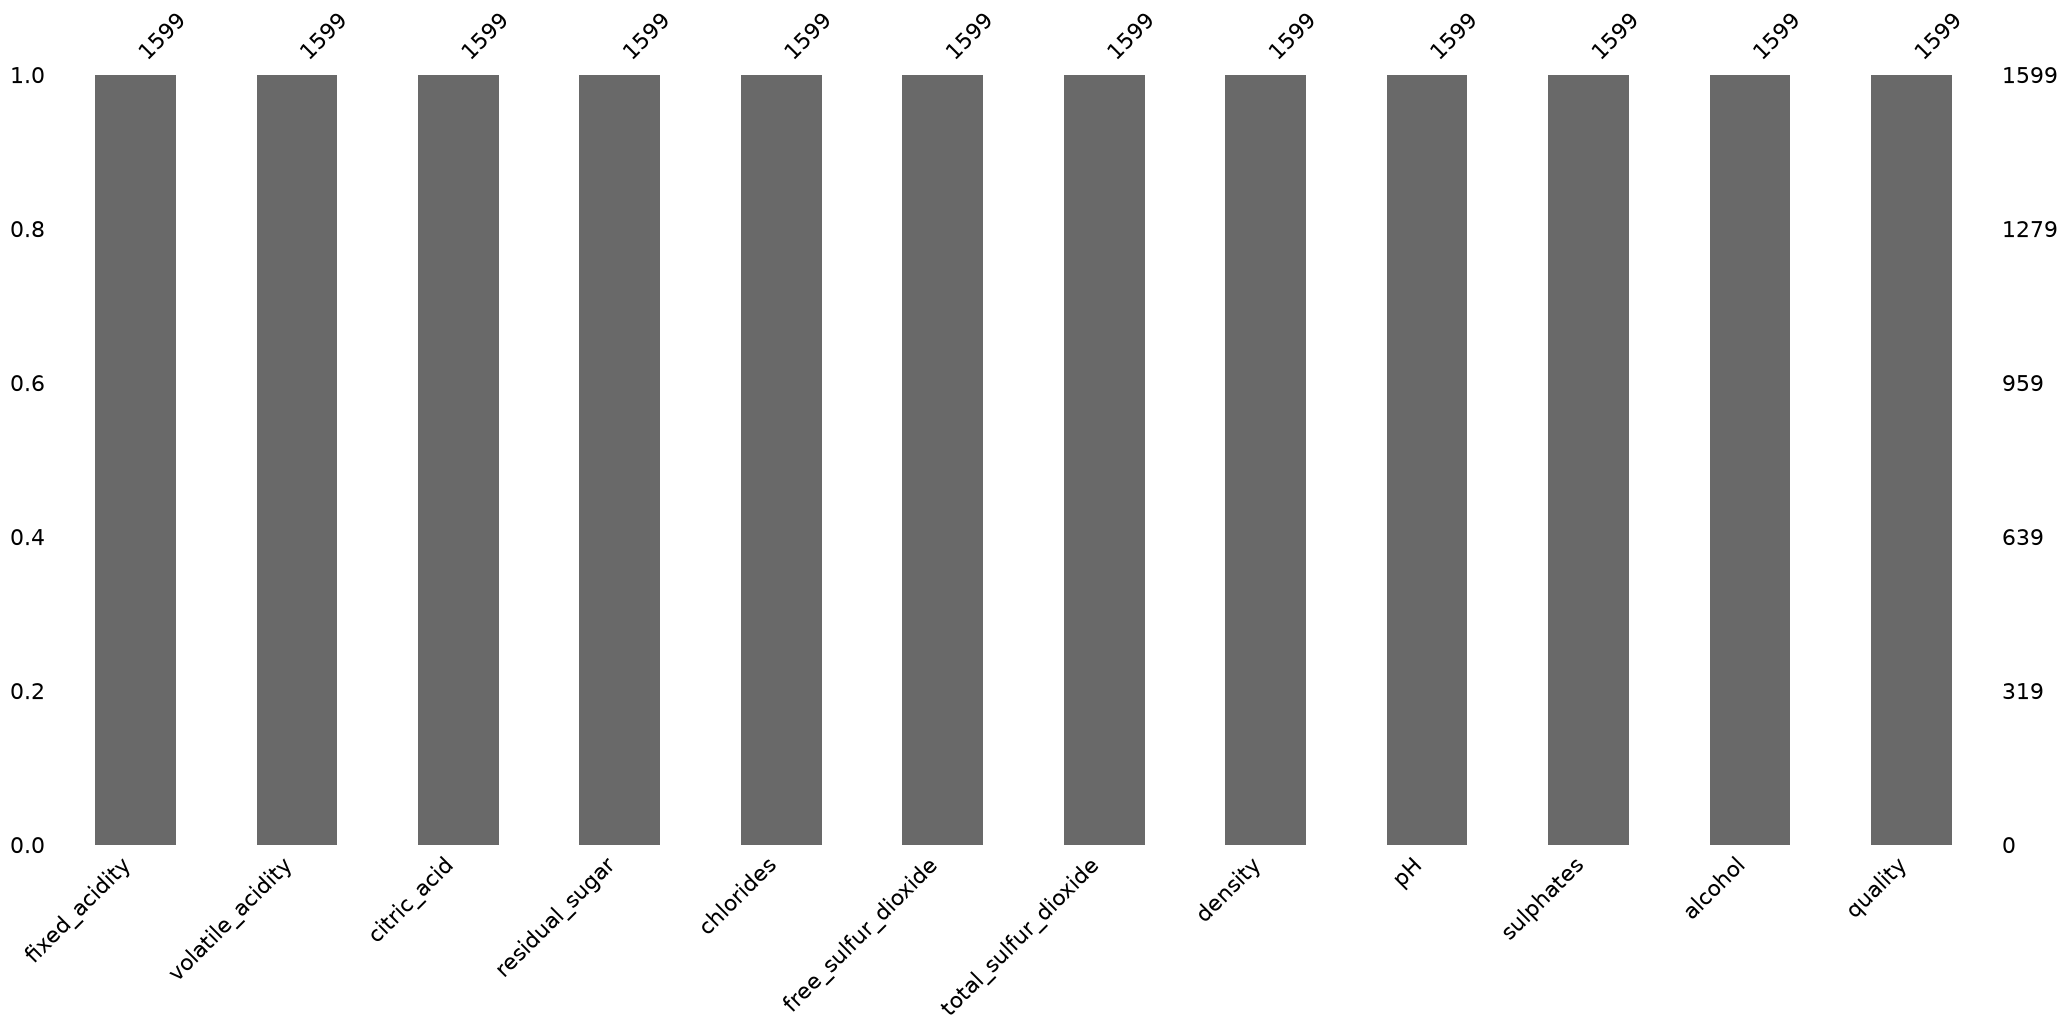

In [32]:
# Dataset 1: Vin Rouge
print(df_red.shape)
print("Valeurs manquantes :", df_red.isna().sum().sum())
msno.bar(df_red);

(4898, 12)
Valeurs manquantes : 0


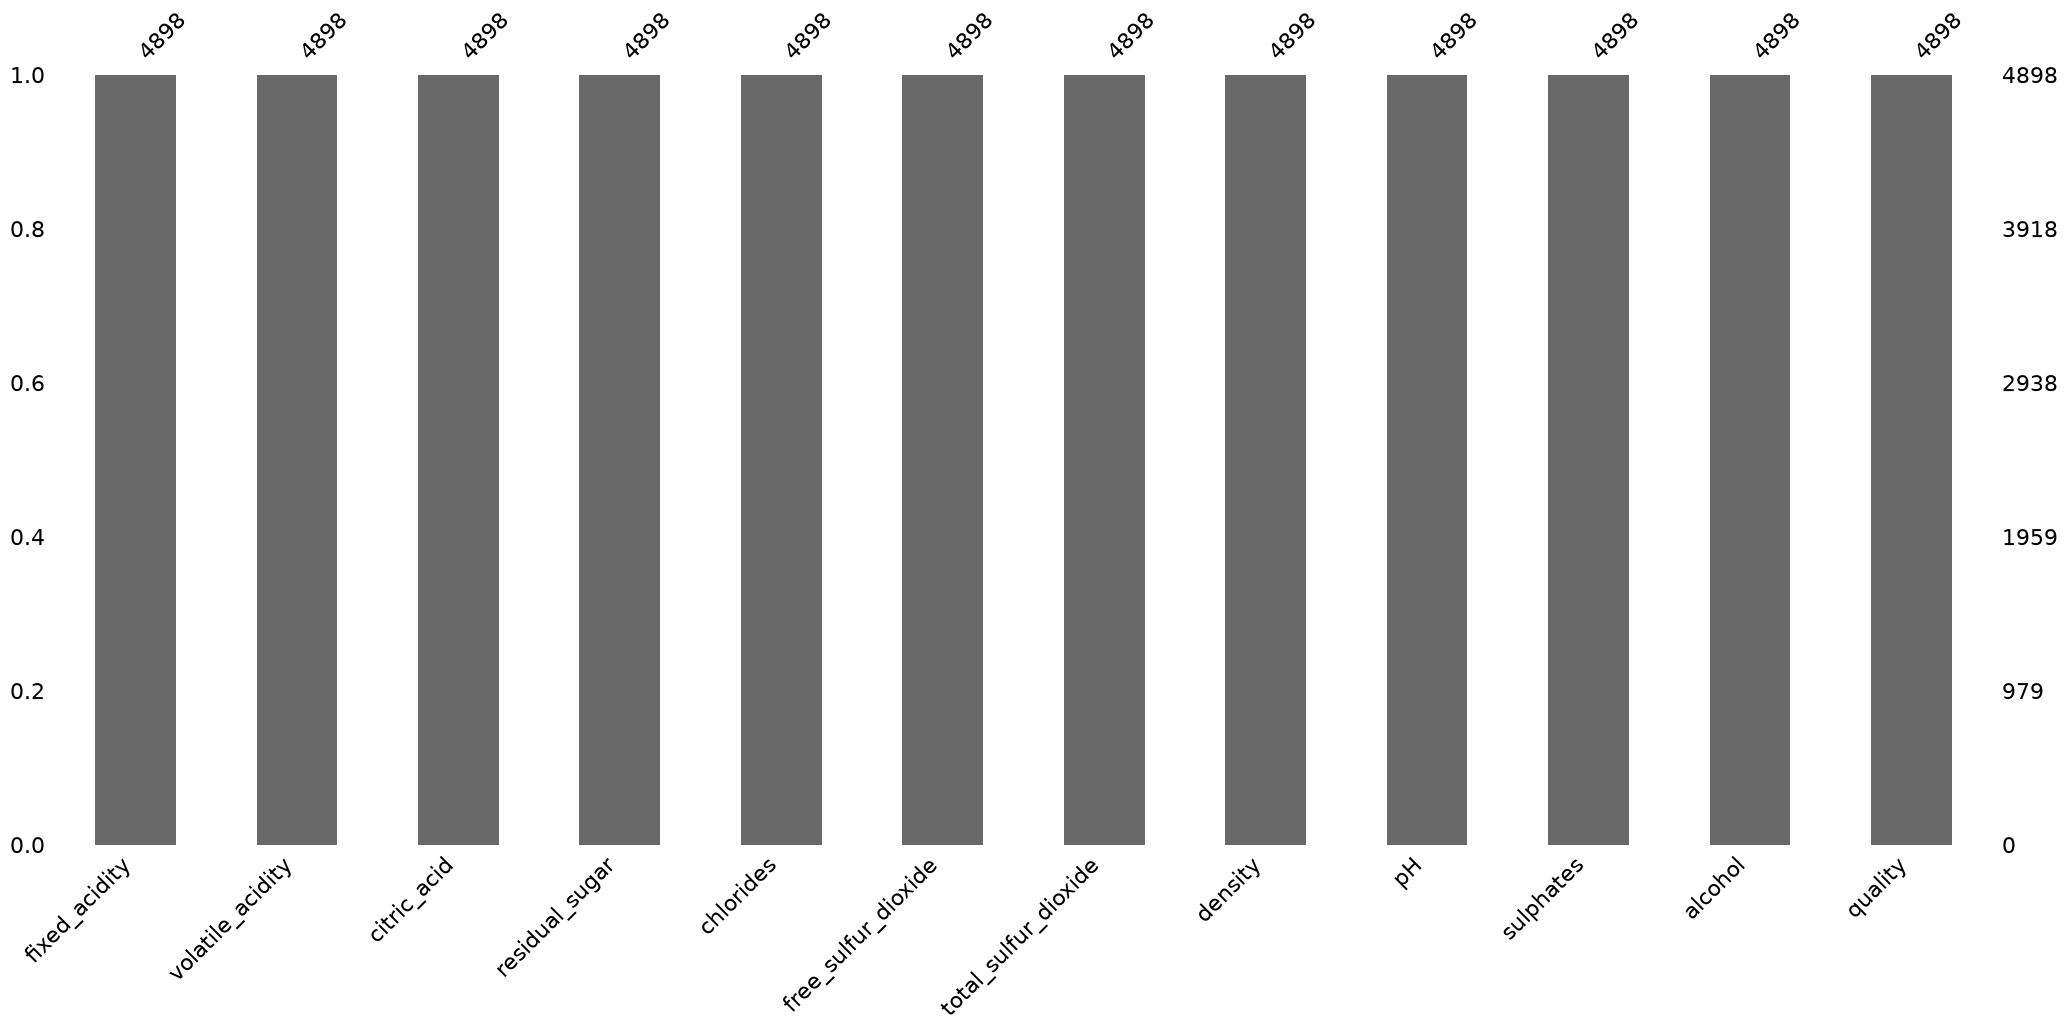

In [36]:
# Dataset 2: Vin Blanc
print(df_white.shape)
print("Valeurs manquantes :", df_white.isna().sum().sum())
msno.bar(df_white);

On constate qu'il n'y a pas de valeurs manquantes dans les jeux de données comme annoncé par la documentation.

##### Gestion des doublons

In [39]:
print("Lignes en double du jeux de data vin rouge :",
      df_red.duplicated().sum(),
      f"({df_red.duplicated().mean():.1%})")
# Supression des doublons
df_red = df_red.drop_duplicates().reset_index(drop=True)
print("Après suppression des doublons :", df_red.shape)

Lignes en double du jeux de data vin rouge : 240 (15.0%)
Après suppression des doublons : (1359, 12)


In [38]:
print("Lignes en double du jeux de data vin blanc :",
      df_white.duplicated().sum(),
      f"({df_white.duplicated().mean():.1%})")
# Supression des doublons
df_white = df_white.drop_duplicates().reset_index(drop=True)
print("Après suppression des doublons :", df_white.shape)

Lignes en double du jeux de data vin blanc : 937 (19.1%)
Après suppression des doublons : (3961, 12)


Il est impératif de supprimer les doublons pour éviter une fuite de données lors de l'évaluation des modèles.

#####

In [40]:
print(df_red.describe())

       fixed_acidity  volatile_acidity  citric_acid  residual_sugar  \
count    1359.000000       1359.000000  1359.000000     1359.000000   
mean        8.310596          0.529478     0.272333        2.523400   
std         1.736990          0.183031     0.195537        1.352314   
min         4.600000          0.120000     0.000000        0.900000   
25%         7.100000          0.390000     0.090000        1.900000   
50%         7.900000          0.520000     0.260000        2.200000   
75%         9.200000          0.640000     0.430000        2.600000   
max        15.900000          1.580000     1.000000       15.500000   

         chlorides  free_sulfur_dioxide  total_sulfur_dioxide      density  \
count  1359.000000          1359.000000           1359.000000  1359.000000   
mean      0.088124            15.893304             46.825975     0.996709   
std       0.049377            10.447270             33.408946     0.001869   
min       0.012000             1.000000         

In [41]:
print(df_white.describe())

       fixed_acidity  volatile_acidity  citric_acid  residual_sugar  \
count    3961.000000       3961.000000  3961.000000     3961.000000   
mean        6.839346          0.280538     0.334332        5.914819   
std         0.866860          0.103437     0.122446        4.861646   
min         3.800000          0.080000     0.000000        0.600000   
25%         6.300000          0.210000     0.270000        1.600000   
50%         6.800000          0.260000     0.320000        4.700000   
75%         7.300000          0.330000     0.390000        8.900000   
max        14.200000          1.100000     1.660000       65.800000   

         chlorides  free_sulfur_dioxide  total_sulfur_dioxide      density  \
count  3961.000000          3961.000000           3961.000000  3961.000000   
mean      0.045905            34.889169            137.193512     0.993790   
std       0.023103            17.210021             43.129065     0.002905   
min       0.009000             2.000000         